# This notebook contains the demo of experiments with SCAG models on the AI4I-2021 dataset

# Step 0. Setup the experiment

In [1]:
import os
import json
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 6) 

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from ignite.metrics import Accuracy, Precision, Recall, Loss, ClassificationReport, ConfusionMatrix
from ignite.engine import create_supervised_evaluator

from scag_models import ParametrizedMLP, ParametrizedCNN, ParametrizedRNN

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
models_path = os.path.join('models', 'scag')
batch_size = 64

metrics = {
    'accuracy': Accuracy(),
    'precision': Precision(average='macro'),
    'recall': Recall(average='macro'),
    'loss': Loss(nn.CrossEntropyLoss()),
    'report': ClassificationReport(),
    # off, on, cap, out, unb, c25-75, vnt (7 classes)
    'confusion': ConfusionMatrix(num_classes=7),
}

## Function to pretty print classification reports

In [2]:
# the AI4I-2021 dataset
mapping = {
    '0': 'off',
    '1': 'on',
    '2': 'cap',
    '3': 'out',
    '4': 'unb',
    '5': 'c25-75',
    '6': 'vnt',
}

def create_and_show_classification_report(data):
    # swapping 0-6 with actual label names
    data = {mapping.get(k, k): v for k, v in data.items()}

    data_df = pd.DataFrame(data).transpose()
    print(f'Classification report:\n{data_df}')

## Function to show beatiful figure of confusion matrix

In [3]:
def create_and_show_confusion_matrix(data):
    sns.heatmap(
        data, 
        annot=True,
        fmt='d',
        cmap='Blues',
        linewidths=0.5,
        linecolor='gray',
        cbar=True,
        xticklabels=[mapping[str(i)] for i in range(data.shape[1])],
        yticklabels=[mapping[str(i)] for i in range(data.shape[0])]
    )

    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix', fontweight='bold')
    plt.tight_layout() 
    plt.show()

# Step 1. Load models

Connected with Table 4, classification models MLP-1, CNN-1, BiGRU-1

## Pretrained MLP-1

In [4]:
with open(os.path.join(models_path, 'MLP-1.json')) as f:
    mlp1_params = json.load(f)

mlp1 = ParametrizedMLP(**mlp1_params).to(device)

mlp1_checkpoint = torch.load(os.path.join(models_path, 'MLP-1.pt'), map_location=device)
mlp1.load_state_dict(mlp1_checkpoint)

print(mlp1)

ParametrizedMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Linear(in_features=540, out_features=224, bias=True)
    (1): BatchNorm1d(224, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.24236281625427009, inplace=False)
    (4): Linear(in_features=224, out_features=112, bias=True)
    (5): BatchNorm1d(112, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): Dropout(p=0.24236281625427009, inplace=False)
    (8): Linear(in_features=112, out_features=56, bias=True)
    (9): BatchNorm1d(56, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Dropout(p=0.24236281625427009, inplace=False)
    (12): Linear(in_features=56, out_features=7, bias=True)
  )
)


## Pretrained CNN-1

In [5]:
with open(os.path.join(models_path, 'CNN-1.json')) as f:
    cnn1_params = json.load(f)

cnn1 = ParametrizedCNN(**cnn1_params).to(device)

cnn1_checkpoint = torch.load(os.path.join(models_path, 'CNN-1.pt'), map_location=device)
cnn1.load_state_dict(cnn1_checkpoint)

print(cnn1)

ParametrizedCNN(
  (features): Sequential(
    (0): Conv2d(1, 256, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2))
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): PReLU(num_parameters=256)
    (3): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (4): Dropout2d(p=0.17200901088286924, inplace=False)
    (5): Conv2d(256, 128, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2))
    (6): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): PReLU(num_parameters=128)
    (8): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (9): Dropout2d(p=0.17200901088286924, inplace=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=1)
  (classifier): Linear(in_features=128, out_features=7, bias=True)
)


## Pretrained BiGRU-1

In [6]:
with open(os.path.join(models_path, 'BiGRU-1.json')) as f:
    bigru1_params = json.load(f)

bigru1 = ParametrizedRNN(**bigru1_params).to(device)

bigru1_checkpoint = torch.load(os.path.join(models_path, 'BiGRU-1.pt'), map_location=device)
bigru1.load_state_dict(bigru1_checkpoint)

print(bigru1)

ParametrizedRNN(
  (batchnorm): BatchNorm1d(18, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (rnn): GRU(18, 256, num_layers=3, batch_first=True, dropout=0.5464851523868264, bidirectional=True)
  (final_dropout): Dropout(p=0.595160872715048, inplace=False)
  (classifier): Linear(in_features=512, out_features=7, bias=True)
)


# Step 2. Validate pretrained models

Connected with Table 4, classification models MLP-1, CNN-1, BiGRU-1

## Validation dataset

In [7]:
X_valid = np.load(os.path.join('real_data', 'X_valid.npy'))
y_valid = np.load(os.path.join('real_data', 'y_valid.npy'))
print(f'X_valid: {X_valid.shape}, y_valid: {y_valid.shape}' )

Xv_tensor = torch.tensor(X_valid, dtype=torch.float32).to(device)
yv_tensor = torch.tensor(y_valid, dtype=torch.long).to(device)

dataset_valid = TensorDataset(Xv_tensor, yv_tensor)
loader_valid = DataLoader(dataset_valid, batch_size=batch_size)

# 2-dimensional CNN
Xv_tensor_cnn = Xv_tensor.unsqueeze(1)
dataset_valid_cnn = TensorDataset(Xv_tensor_cnn, yv_tensor)
loader_valid_cnn = DataLoader(dataset_valid_cnn, batch_size=batch_size)

X_valid: (2901, 30, 18), y_valid: (2901,)


## MLP-1 validation

In [8]:
mlp1_evaluator = create_supervised_evaluator(mlp1, metrics=metrics, device=device)
mlp1_evaluator.run(loader_valid)
mlp1_metrics_valid = mlp1_evaluator.state.metrics.copy()

for key, value in mlp1_metrics_valid.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.8831437435367114
precision: 0.8897107445160896
recall: 0.891648750770743
loss: 0.28408033968620733


## CNN-1 validation

In [9]:
cnn1_evaluator = create_supervised_evaluator(cnn1, metrics=metrics, device=device)
cnn1_evaluator.run(loader_valid_cnn)
cnn1_metrics_valid = cnn1_evaluator.state.metrics.copy()

for key, value in cnn1_metrics_valid.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.8910720441227163
precision: 0.8997674331009327
recall: 0.889073283976149
loss: 0.30853361953582814


## BiGRU-1 validation

In [10]:
bigru1_evaluator = create_supervised_evaluator(bigru1, metrics=metrics, device=device)
bigru1_evaluator.run(loader_valid)
bigru1_metrics_valid = bigru1_evaluator.state.metrics.copy()

for key, value in bigru1_metrics_valid.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.8790072388831437
precision: 0.8882119747969044
recall: 0.8791095470098041
loss: 0.36245280452861084


# Step 3. Test pretrained models on real data

Connected with Table 6, the AI4I-2021 dataset

## Test dataset

In [11]:
X_test = np.load(os.path.join('real_data', 'X_test.npy'))
y_test = np.load(os.path.join('real_data', 'y_test.npy'))
print(f'X_test: {X_test.shape}, y_test: {y_test.shape}' )

Xt_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
yt_tensor = torch.tensor(y_test, dtype=torch.long).to(device)

dataset_test = TensorDataset(Xt_tensor, yt_tensor)
loader_test = DataLoader(dataset_test, batch_size=batch_size)

# 2-dimensional CNN
Xt_tensor_cnn = Xt_tensor.unsqueeze(1)
dataset_test_cnn = TensorDataset(Xt_tensor_cnn, yt_tensor)
loader_test_cnn = DataLoader(dataset_test_cnn, batch_size=batch_size)

X_test: (6401, 30, 18), y_test: (6401,)


## MLP-1 testing

accuracy: 0.8701765349164193
loss: 0.3250522074187627

Classification report:
           precision    recall  f1-score
off         1.000000  1.000000  1.000000
on          0.849568  0.878827  0.863950
cap         0.853030  0.720871  0.781402
out         0.825378  0.868873  0.846567
unb         0.717149  0.821429  0.765755
c25-75      0.862160  0.827608  0.844531
vnt         1.000000  1.000000  1.000000
macro avg   0.872470  0.873944  0.871744


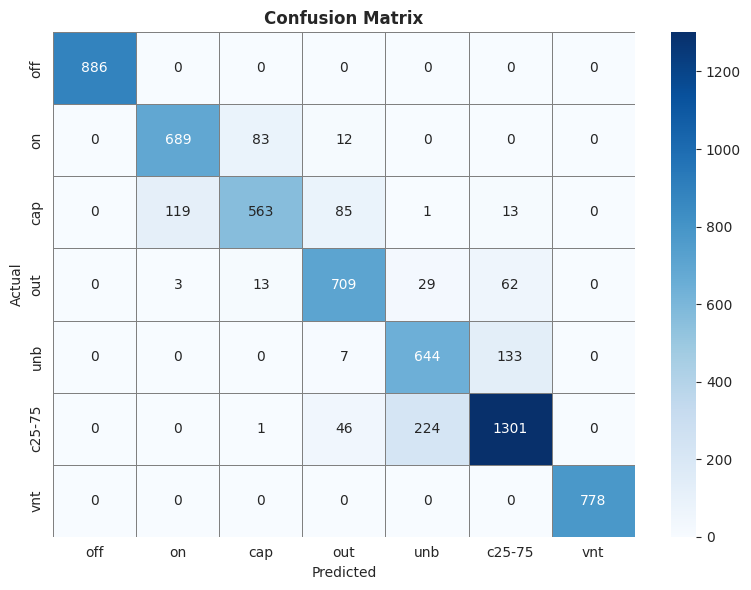

In [12]:
mlp1_evaluator.run(loader_test)
mlp1_metrics_test = mlp1_evaluator.state.metrics.copy()

for key, value in mlp1_metrics_test.items():
    print(f'{key}: {value}') if key in ['accuracy', 'loss'] else None
print()

mlp1_cr_test = json.loads(mlp1_metrics_test["report"])
create_and_show_classification_report(mlp1_cr_test)

mlp1_cm_test = mlp1_metrics_test["confusion"].numpy()
create_and_show_confusion_matrix(mlp1_cm_test)

## CNN-1 testing

accuracy: 0.8936103733791595
loss: 0.27508877702214496

Classification report:
           precision    recall  f1-score
off         1.000000  1.000000  1.000000
on          0.903585  0.932398  0.917765
cap         0.891817  0.823303  0.856192
out         0.852399  0.849265  0.850829
unb         0.788251  0.735969  0.761214
c25-75      0.849579  0.898219  0.873222
vnt         1.000000  1.000000  1.000000
macro avg   0.897947  0.891308  0.894174


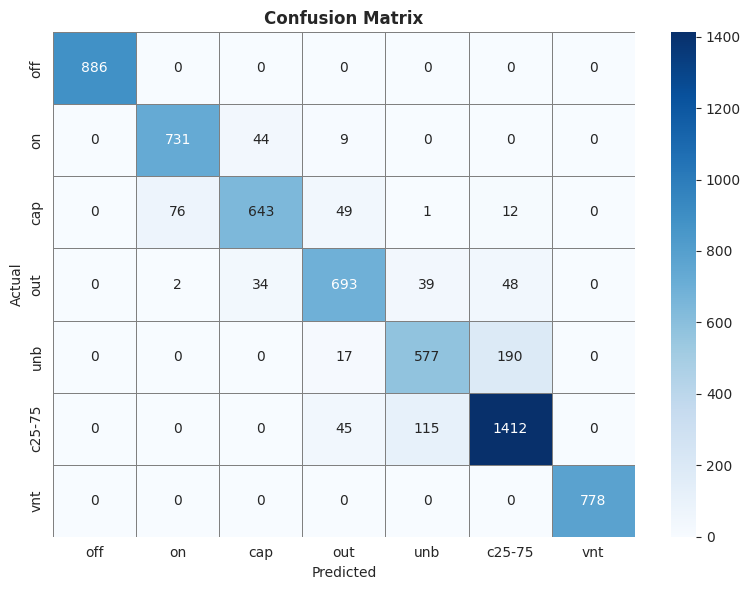

In [13]:
cnn1_evaluator.run(loader_test_cnn)
cnn1_metrics_test = cnn1_evaluator.state.metrics.copy()

for key, value in cnn1_metrics_test.items():
    print(f'{key}: {value}') if key in ['accuracy', 'loss'] else None
print()

cnn1_cr_test = json.loads(cnn1_metrics_test["report"])
create_and_show_classification_report(cnn1_cr_test)

cnn1_cm_test = cnn1_metrics_test["confusion"].numpy()
create_and_show_confusion_matrix(cnn1_cm_test)

## BiGRU-1 testing

accuracy: 0.8423683799406343
loss: 0.4502559567108655

Classification report:
           precision    recall  f1-score
off         1.000000  1.000000  1.000000
on          0.955592  0.741071  0.834770
cap         0.744843  0.878361  0.806110
out         0.819425  0.734069  0.774402
unb         0.691635  0.706633  0.699054
c25-75      0.780430  0.832061  0.805419
vnt         1.000000  1.000000  1.000000
macro avg   0.855989  0.841742  0.845679


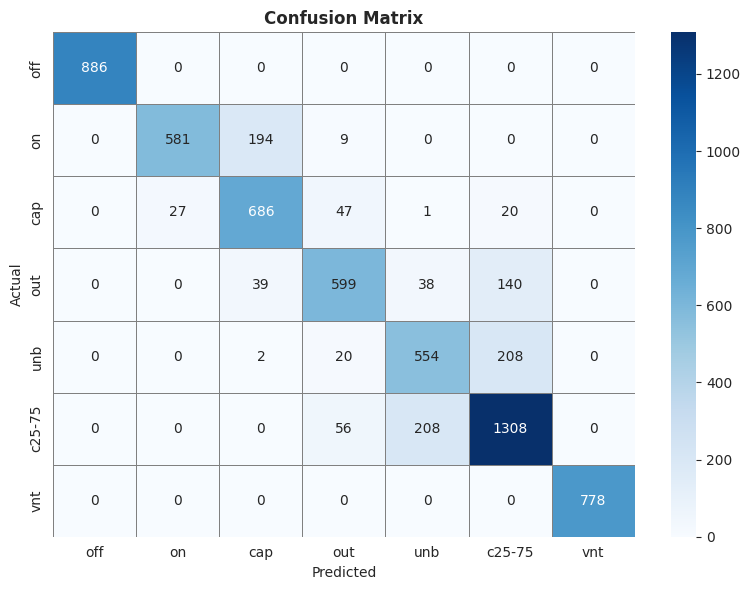

In [49]:
bigru1_evaluator.run(loader_test)
bigru1_metrics_test = bigru1_evaluator.state.metrics.copy()

for key, value in bigru1_metrics_test.items():
    print(f'{key}: {value}') if key in ['accuracy', 'loss'] else None
print()

bigru1_cr_test = json.loads(bigru1_metrics_test["report"])
create_and_show_classification_report(bigru1_cr_test)

bigru1_cm_test = bigru1_metrics_test["confusion"].numpy()
create_and_show_confusion_matrix(bigru1_cm_test)

# Step 4. Test pretrained models on predicted data

Connected with Table 8, the AI4I-2021 dataset

## Predicted datasets by models GRU-1, GRU3 and LSTM-1

In [14]:
datasets = {'X': {}, 'y': {}, 'Xt': {}, 'yt': {}, 'd': {}, 'l': {}, 'l_cnn': {}}
X_names = ["GRU-1_X_pred", "GRU-3_X_pred", "LSTM-1_X_pred"]
y_names = ["GRU-1_y_pred", "GRU-3_y_pred", "LSTM-1_y_pred"]
d_names = ["GRU-1_pred_dataset", "GRU-3_pred_dataset", "LSTM-1_pred_dataset"]
l_names = ["GRU-1_pred_loader", "GRU-3_pred_loader", "LSTM-1_pred_loader"]
l_cnn_names = ["GRU-1_pred_loader_cnn", "GRU-3_pred_loader_cnn", "LSTM-1_pred_loader_cnn"]

for X_name, y_name, dataset_name, loader_name, loader_cnn_name in zip(
    X_names, y_names, d_names, l_names, l_cnn_names
):
    datasets['X'][X_name] = np.load(os.path.join('pred_data', f"{X_name}.npy"))
    datasets['y'][y_name] = np.load(os.path.join('pred_data', f"{y_name}.npy"))
    print(f"{X_name}: {datasets['X'][X_name].shape}, {y_name}: {datasets['y'][y_name].shape}")
    
    datasets['Xt'][X_name] = torch.tensor(datasets['X'][X_name], dtype=torch.float32).to(device)
    datasets['yt'][y_name] = torch.tensor(datasets['y'][y_name], dtype=torch.long).to(device)
    
    datasets['d'][dataset_name] = TensorDataset(datasets['Xt'][X_name], datasets['yt'][y_name])
    datasets['l'][loader_name] = DataLoader(datasets['d'][dataset_name], batch_size=batch_size)
    
    datasets['Xt'][X_name] = datasets['Xt'][X_name].unsqueeze(1)
    datasets['d'][dataset_name] = TensorDataset(datasets['Xt'][X_name], datasets['yt'][y_name])
    datasets['l_cnn'][loader_cnn_name] = DataLoader(datasets['d'][dataset_name], batch_size=batch_size)
    
(GRU1_loader_pred, GRU3_loader_pred, LSTM1_loader_pred) = [datasets['l'][key] for key in l_names]
(GRU1_loader_pred_cnn, GRU3_loader_pred_cnn, LSTM1_loader_pred_cnn) = [datasets['l_cnn'][key] for key in l_cnn_names]

GRU-1_X_pred: (6401, 30, 18), GRU-1_y_pred: (6401,)
GRU-3_X_pred: (6401, 30, 18), GRU-3_y_pred: (6401,)
LSTM-1_X_pred: (6401, 30, 18), LSTM-1_y_pred: (6401,)


## GRU-1 (SPAg) and MLP-1 (SCAg) testing 

In [31]:
mlp1_evaluator.run(GRU1_loader_pred)
gru1_mlp1_metrics_pred = mlp1_evaluator.state.metrics.copy()

for key, value in gru1_mlp1_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.8289329792219966
precision: 0.904036505926019
recall: 0.8004803608945411
loss: 0.5668977350951023


## GRU-1 (SPAg) and CNN-1 (SCAg) testing

In [32]:
cnn1_evaluator.run(GRU1_loader_pred_cnn)
gru1_cnn1_metrics_pred = cnn1_evaluator.state.metrics.copy()

for key, value in gru1_cnn1_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.833463521324793
precision: 0.9051845273128248
recall: 0.806000653437615
loss: 0.7669883123730667


## GRU-1 (SPAg) and BiGRU-1 (SCAg) testing

In [29]:
bigru1_evaluator.run(GRU1_loader_pred)
gru1_bigru1_metrics_pred = bigru1_evaluator.state.metrics.copy()

for key, value in gru1_bigru1_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.8717387908139353
precision: 0.9155303263446306
recall: 0.8541313415729987
loss: 0.5143896888669739


## GRU-3 (SPAg) and MLP-1 (SCAg) testing

In [28]:
mlp1_evaluator.run(GRU3_loader_pred)
gru3_mlp1_metrics_pred = mlp1_evaluator.state.metrics.copy()

for key, value in gru3_mlp1_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.8239337603499454
precision: 0.7599669200368016
recall: 0.7942447153343343
loss: 0.7195754478060069


## GRU-3 (SPAg) and CNN-1 (SCAg) testing

In [30]:
cnn1_evaluator.run(GRU3_loader_pred_cnn)
gru3_cnn1_metrics_pred = cnn1_evaluator.state.metrics.copy()

for key, value in gru3_cnn1_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.8348695516325574
precision: 0.7645154024432893
recall: 0.8068584576687818
loss: 1.052324282826902


## GRU-3 (SPAg) and BiGRU-1 (SCAg) testing

In [27]:
bigru1_evaluator.run(GRU3_loader_pred)
gru3_bigru1_metrics_pred = bigru1_evaluator.state.metrics.copy()

for key, value in gru3_bigru1_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.8562724574285268
precision: 0.7717598356294838
recall: 0.8337146745284809
loss: 0.961987293245196


## LSTM-1 (SPAg) and MLP-1 (SCAg) testing

In [26]:
mlp1_evaluator.run(LSTM1_loader_pred)
lstm1_mlp1_metrics_pred = mlp1_evaluator.state.metrics.copy()

for key, value in lstm1_mlp1_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.8433057334791438
precision: 0.9103297118404027
recall: 0.8171284946718079
loss: 0.5425236443768552


## LSTM-1 (SPAg) and CNN-1 (SCAg) testing

In [25]:
cnn1_evaluator.run(LSTM1_loader_pred_cnn)
lstm1_cnn1_metrics_pred = cnn1_evaluator.state.metrics.copy()

for key, value in lstm1_cnn1_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.8483049523511951
precision: 0.9115970213676953
recall: 0.8231489140993654
loss: 0.6751436085426106


## LSTM-1 (SPAg) and BiGRU-1 (SCAg) testing

In [24]:
bigru1_evaluator.run(LSTM1_loader_pred)
lstm1_bigru1_metrics_pred = bigru1_evaluator.state.metrics.copy()

for key, value in lstm1_bigru1_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.885955319481331
precision: 0.9194326016256621
recall: 0.8723053691572709
loss: 0.44156274257684347


# This is the end of the demo for the AI4I-2021 dataset